# Sales & Product Segmentation (K-Means)

Tujuan: mengelompokkan produk berdasarkan karakteristik penjualannya.

- Input: `Items`, `TotalItem`, `NetSales`, `Outlet`, `Date`
- Metode: **K-Means Clustering**
- Output: kategori produk berdasarkan performa
  **Best Seller**, **Regular Seller**, **Seasonal Product**, **Slow Moving**

Setiap produk dicirikan oleh tujuh ukuran yang dihitung langsung dari transaksi:

| Fitur | Arti |
|---|---|
| `qty_per_day` | rata-rata item terjual per hari |
| `rev_per_day` | rata-rata NetSales per hari (kontribusi omzet) |
| `price_per_item` | NetSales dibagi jumlah item (nilai per item) |
| `cv_daily` | koefisien variasi penjualan harian (semakin besar semakin naik-turun) |
| `momentum` | kemiringan tren dibagi rata-rata harian (arah pertumbuhan) |
| `seasonal_strength` | kekuatan pola mingguan hasil dekomposisi STL |
| `weekend_ratio` | rata-rata akhir pekan dibagi hari kerja |

Hasil disimpan di `artifacts/product_segmentation/`.

## 1. Konfigurasi

In [1]:
import json
import pickle
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

DATA_PATH = Path("..") / "data" / "Transactions.csv"
OUTPUT_DIR = Path("..") / "artifacts" / "product_segmentation"
MODEL_PATH = OUTPUT_DIR / "model.pkl"
METADATA_PATH = OUTPUT_DIR / "metadata.json"

CLUSTERS = 4        # jumlah kategori yang diminta
SEASON_LENGTH = 7   # pola mingguan
SEED = 42

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("pandas      :", pd.__version__)
print("folder hasil:", OUTPUT_DIR.resolve())

pandas      : 3.1.0
folder hasil: D:\KULIAH\SMT_5\PBL\ProjectBasedLearning_MyVentory\ML\artifacts\product_segmentation


## 2. Membongkar daftar item

Kolom `Items` berisi beberapa nama produk yang dipisah koma dalam satu struk.
Kolom itu dipecah supaya setiap baris mewakili satu item terjual.

In [2]:
transactions = pd.read_csv(DATA_PATH, parse_dates=["Date"])

lines = transactions[["Date", "Outlet", "Items", "TotalItem", "NetSales"]].copy()
lines["ProductName"] = lines.Items.str.split(",")
lines = lines.explode("ProductName")
lines["ProductName"] = lines.ProductName.str.strip()
lines["one"] = 1

assert lines.ProductName.notna().all(), "ada nama produk kosong"
assert len(lines) == transactions.TotalItem.sum(), "jumlah baris tidak sama dengan TotalItem"

print(f"baris transaksi asli   : {len(transactions):,}")
print(f"baris item setelah pecah: {len(lines):,}")
print(f"jumlah produk unik     : {lines.ProductName.nunique()}")
print(f"rentang tanggal        : {lines.Date.min().date()} s/d {lines.Date.max().date()}")

baris transaksi asli   : 53,820
baris item setelah pecah: 61,973
jumlah produk unik     : 94
rentang tanggal        : 2025-01-02 s/d 2025-09-30


## 3. Matriks produk x hari

Tabel ini menjadi sumber semua fitur: baris = tanggal, kolom = produk, isi = jumlah item terjual.

In [3]:
matrix = (
    lines.pivot_table(index="Date", columns="ProductName", values="one", aggfunc="sum")
    .asfreq("D")
    .fillna(0)
)

print("bentuk matriks produk x hari:", matrix.shape)
print(f"hari tanpa penjualan sama sekali: {int((matrix.sum(axis=1) == 0).sum())}")
print()
print(matrix.iloc[:3, :5].astype(int).to_string())

bentuk matriks produk x hari: (272, 94)
hari tanpa penjualan sama sekali: 0

ProductName  Air Mineral  Americano (Hot Arabica)  Americano (Hot Houseblend)  Americano (Ice Arabica)  Americano (Ice Houesblend)
Date                                                                                                                              
2025-01-02             2                        3                           2                        2                           3
2025-01-03             2                        3                           3                        4                           2
2025-01-04             0                        2                           4                        4                           3


## 4. Membentuk fitur tiap produk

Semua angka di bawah dihitung dari transaksi, tidak ada nilai yang dikarang.

In [4]:
import numpy as np

revenue = lines.groupby("ProductName").NetSales.sum()
quantity = matrix.sum()

features = pd.DataFrame({"quantity": quantity, "revenue": revenue})
features["qty_per_day"] = features.quantity / len(matrix)
features["rev_per_day"] = features.revenue / len(matrix)
features["price_per_item"] = features.revenue / features.quantity
features["cv_daily"] = matrix.std() / matrix.mean()
features["active_ratio"] = (matrix > 0).mean()
features["weekend_ratio"] = (
    matrix[matrix.index.dayofweek >= 5].mean() / matrix[matrix.index.dayofweek < 5].mean()
)
features["trend_slope"] = [
    np.polyfit(np.arange(len(matrix)), matrix[product].rolling(7, min_periods=1).mean(), 1)[0]
    for product in matrix.columns
]
features["momentum"] = features.trend_slope / features.qty_per_day * 100

print(f"produk dianalisis: {len(features)}")
print()
print(features[["quantity", "revenue", "price_per_item", "cv_daily", "weekend_ratio", "momentum"]].describe().round(2).to_string())

produk dianalisis: 94

       quantity      revenue  price_per_item  cv_daily  weekend_ratio  momentum
count     94.00        94.00           94.00     94.00          94.00     94.00
mean     659.29  16041671.54        24322.19      0.66           1.00      0.03
std       26.43   3603157.32         5312.59      0.03           0.09      0.05
min      590.00   5653153.37         8099.07      0.57           0.81     -0.10
25%      641.75  15218243.34        23454.30      0.64           0.93     -0.00
50%      657.00  16468468.60        25016.52      0.67           1.00      0.03
75%      679.75  17852702.84        26707.67      0.68           1.06      0.07
max      715.00  22018018.03        31485.97      0.75           1.21      0.13


In [5]:
from statsmodels.tsa.seasonal import STL

strength = []
for product in matrix.columns:
    series = matrix[product]
    decomposition = STL(series, period=SEASON_LENGTH, robust=True).fit()
    strength.append(max(0.0, 1 - decomposition.resid.var() / series.var()))

features["seasonal_strength"] = strength

print("kekuatan pola mingguan per produk:")
print(features.seasonal_strength.describe().round(3).to_string())

kekuatan pola mingguan per produk:
count    94.000
mean      0.289
std       0.072
min       0.120
25%       0.238
50%       0.289
75%       0.334
max       0.436


In [6]:
print("Sebaran antar produk (nilai terbesar dibagi terkecil):")
for column in ["quantity", "revenue", "price_per_item", "cv_daily", "weekend_ratio", "seasonal_strength"]:
    ratio = features[column].max() / features[column].min()
    print(f"  {column:<18} {ratio:>5.2f}x")
print()
print("Catatan: sebaran quantity hanya sekitar 1.2x, artinya semua produk terjual")
print("dalam jumlah yang hampir sama. Yang membedakan produk terutama nilai per item,")
print("arah tren, dan pola akhir pekan.")

Sebaran antar produk (nilai terbesar dibagi terkecil):
  quantity            1.21x
  revenue             3.89x
  price_per_item      3.89x
  cv_daily            1.30x
  weekend_ratio       1.50x
  seasonal_strength   3.63x

Catatan: sebaran quantity hanya sekitar 1.2x, artinya semua produk terjual
dalam jumlah yang hampir sama. Yang membedakan produk terutama nilai per item,
arah tren, dan pola akhir pekan.


## 5. Standarisasi fitur

K-Means memakai jarak, sehingga semua fitur disamakan skalanya lebih dulu.

In [7]:
from sklearn.preprocessing import StandardScaler

FEATURES = [
    "qty_per_day",
    "rev_per_day",
    "price_per_item",
    "cv_daily",
    "momentum",
    "seasonal_strength",
    "weekend_ratio",
]

scaler = StandardScaler()
X = scaler.fit_transform(features[FEATURES])

print("bentuk data latih:", X.shape)
print("rata-rata setelah standarisasi:", np.round(X.mean(axis=0), 3).tolist())
print("simpangan baku setelah standarisasi:", np.round(X.std(axis=0), 3).tolist())

bentuk data latih: (94, 7)
rata-rata setelah standarisasi: [0.0, -0.0, 0.0, -0.0, -0.0, 0.0, -0.0]
simpangan baku setelah standarisasi: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


## 6. Memilih jumlah cluster

Dua ukuran dipakai: **inertia** (untuk elbow) dan **silhouette** (semakin tinggi semakin rapat).

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

search = []
for k in range(2, 8):
    model = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
    search.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X, model.labels_),
        "ukuran_cluster": np.bincount(model.labels_).tolist(),
    })

search_table = pd.DataFrame(search)
print(search_table.round(3).to_string(index=False))

 k  inertia  silhouette              ukuran_cluster
 2  518.141       0.278                    [16, 78]
 3  433.063       0.174                [36, 16, 42]
 4  386.119       0.172            [29, 16, 30, 19]
 5  349.529       0.184        [20, 24, 16, 20, 14]
 6  319.432       0.185    [20, 16, 18, 16, 14, 10]
 7  303.059       0.168 [4, 14, 19, 11, 12, 13, 21]


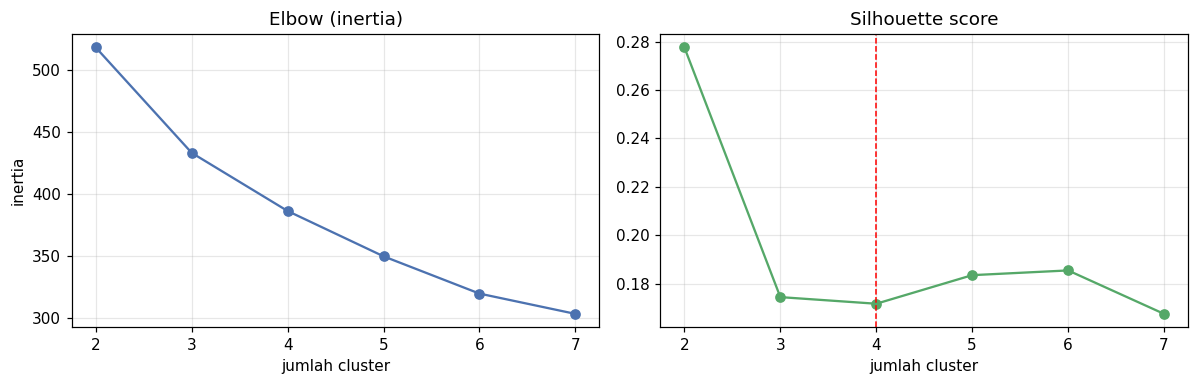

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

axes[0].plot(search_table.k, search_table.inertia, marker="o", color="#4c72b0")
axes[0].set_title("Elbow (inertia)")
axes[0].set_xlabel("jumlah cluster")
axes[0].set_ylabel("inertia")

axes[1].plot(search_table.k, search_table.silhouette, marker="o", color="#55a868")
axes[1].axvline(CLUSTERS, ls="--", color="red", lw=1)
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("jumlah cluster")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_1_elbow_silhouette.png", dpi=120)
plt.show()

In [10]:
print(f"k terpilih: {CLUSTERS}")
print()
print("Alasan: kebutuhan bisnis meminta empat kategori produk. Pada k=4 kurva inertia")
print("mulai melandai dan ukuran cluster cukup berimbang, sehingga struktur empat")
print("kelompok masih bisa dibaca. Silhouette seluruh k bernilai rendah (di bawah 0.30),")
print("yang berarti batas antar kelompok tidak tajam. Hal ini wajar karena sebaran")
print("penjualan antar produk memang sempit, jadi hasil segmentasi dibaca sebagai")
print("kecenderungan, bukan pemisahan yang tegas.")

k terpilih: 4

Alasan: kebutuhan bisnis meminta empat kategori produk. Pada k=4 kurva inertia
mulai melandai dan ukuran cluster cukup berimbang, sehingga struktur empat
kelompok masih bisa dibaca. Silhouette seluruh k bernilai rendah (di bawah 0.30),
yang berarti batas antar kelompok tidak tajam. Hal ini wajar karena sebaran
penjualan antar produk memang sempit, jadi hasil segmentasi dibaca sebagai
kecenderungan, bukan pemisahan yang tegas.


## 7. Melatih K-Means

In [11]:
kmeans = KMeans(n_clusters=CLUSTERS, n_init=50, random_state=SEED).fit(X)

features["cluster"] = kmeans.labels_

print(f"inertia akhir     : {kmeans.inertia_:.2f}")
print(f"silhouette akhir  : {silhouette_score(X, kmeans.labels_):.3f}")
print()
print("jumlah produk per cluster:")
print(features.cluster.value_counts().sort_index().to_string())

inertia akhir     : 386.12
silhouette akhir  : 0.172

jumlah produk per cluster:
cluster
0    29
1    16
2    30
3    19


# Sales & Product Segmentation (DBSCAN)

Tujuan: Mengelompokkan produk berdasarkan kepadatan data transaksi dan mengidentifikasi anomali (*noise*).

- **Input**: Fitur terstandarisasi `X` (7 fitur transaksi produk).
- **Metode**: Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
- **Output**: Klaster berbasis kepadatan data serta label `-1` untuk produk anomali (*outliers*).

| Fitur | Arti |
|---|---|
| `qty_per_day` | Rata-rata item terjual per hari |
| `rev_per_day` | Rata-rata NetSales per hari |
| `price_per_item` | Nilai per item (NetSales / Qty) |
| `cv_daily` | Koefisien variasi penjualan harian |
| `momentum` | Kemiringan tren pertumbuhan |
| `seasonal_strength` | Kekuatan pola mingguan |
| `weekend_ratio` | Rasio penjualan akhir pekan vs hari kerja |

## 1. Estimasi Parameter Optimal (eps & min_samples)
Menggunakan k-distance graph (K-Nearest Neighbors) untuk menemukan titik tekuk (*elbow*) sebagai estimasi nilai `eps` optimal.

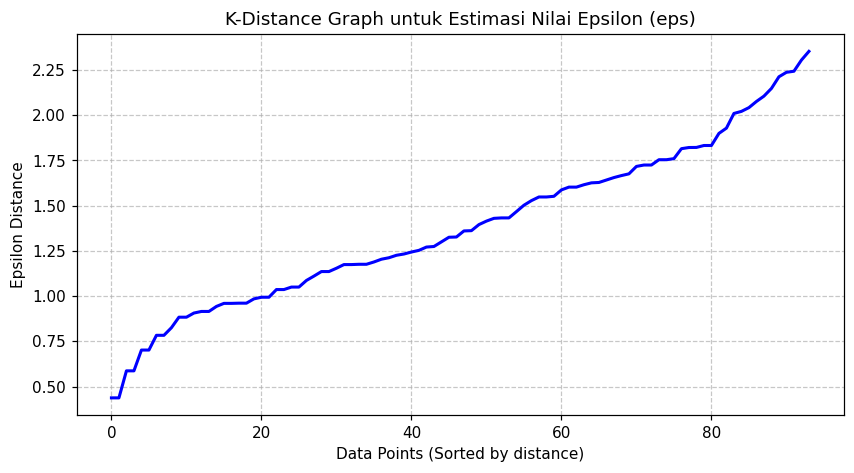

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

# Menghitung jarak ke 2-nearest neighbor
neighbors = NearestNeighbors(n_neighbors=2)
neighbors_fit = neighbors.fit(X)
distances, _ = neighbors_fit.kneighbors(X)

# Sorting jarak untuk plot k-distance
distances = np.sort(distances[:, 1], axis=0)

plt.figure(figsize=(9, 4.5))
plt.plot(distances, color='b', lw=2)
plt.title("K-Distance Graph untuk Estimasi Nilai Epsilon (eps)")
plt.xlabel("Data Points (Sorted by distance)")
plt.ylabel("Epsilon Distance")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


## 2. Pelatihan Model DBSCAN
Menjalankan model DBSCAN menggunakan parameter `eps` dan `min_samples` serta mengukur waktu komputasi yang dibutuhkan.

In [13]:
import time
from sklearn.cluster import DBSCAN

# Melatih model DBSCAN & menghitung waktu eksekusi
start_time = time.time()
dbscan = DBSCAN(eps=1.5, min_samples=3)
db_labels = dbscan.fit_predict(X)
db_time_ms = (time.time() - start_time) * 1000

# Menyimpan hasil ke DataFrame
features["dbscan_cluster"] = db_labels
print(f"Model DBSCAN berhasil dilatih.")
print(f"Waktu Komputasi: {db_time_ms:.2f} ms")


Model DBSCAN berhasil dilatih.
Waktu Komputasi: 3.00 ms


## 3. Identifikasi Klaster & Analisis Noise
Menghitung berapa banyak klaster alami yang berhasil dibentuk serta jumlah data *noise* (anomali) yang terdeteksi.

In [14]:
# Menghitung statistik klaster dan noise
n_clusters_db = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = list(db_labels).count(-1)
coverage_percent = ((len(db_labels) - n_noise) / len(db_labels)) * 100

print(f"Jumlah Klaster Terbentuk : {n_clusters_db}")
print(f"Jumlah Data Noise/Outlier: {n_noise} produk")
print(f"Cakupan Klaster (Coverage): {coverage_percent:.2f}%")


Jumlah Klaster Terbentuk : 5
Jumlah Data Noise/Outlier: 45 produk
Cakupan Klaster (Coverage): 52.13%


## 4. Profiling Hasil Klaster & Outlier
Menampilkan nilai rata-rata dari setiap fitur berdasarkan hasil pengelompokan DBSCAN.

In [15]:
from IPython.display import display

# Menampilkan rata-rata fitur per klaster DBSCAN
db_profile = features.groupby("dbscan_cluster")[FEATURES].mean()
print("Profil Rata-rata Fitur per Klaster DBSCAN:")
display(db_profile.round(3))


Profil Rata-rata Fitur per Klaster DBSCAN:


,qty_per_day,rev_per_day,price_per_item,cv_daily,momentum,seasonal_strength,weekend_ratio
dbscan_cluster,,,,,,,
-1,2.433,56067.097,23020.206,0.656,0.027,0.293,1.014
0,2.424,64318.179,26596.476,0.669,0.051,0.261,1.058
1,2.374,59045.627,24879.126,0.674,0.027,0.299,0.938
2,2.386,39967.542,16744.995,0.702,0.023,0.370,1.021
3,2.473,76658.276,30995.718,0.646,0.019,0.234,0.940
4,2.547,60141.760,23620.406,0.608,0.026,0.347,0.883


## 5. Visualisasi Distribusi DBSCAN (PCA 2D)
Memvisualisasikan hasil pengelompokan DBSCAN dan titik-titik anomali pada ruang komponen utama PCA 2D.

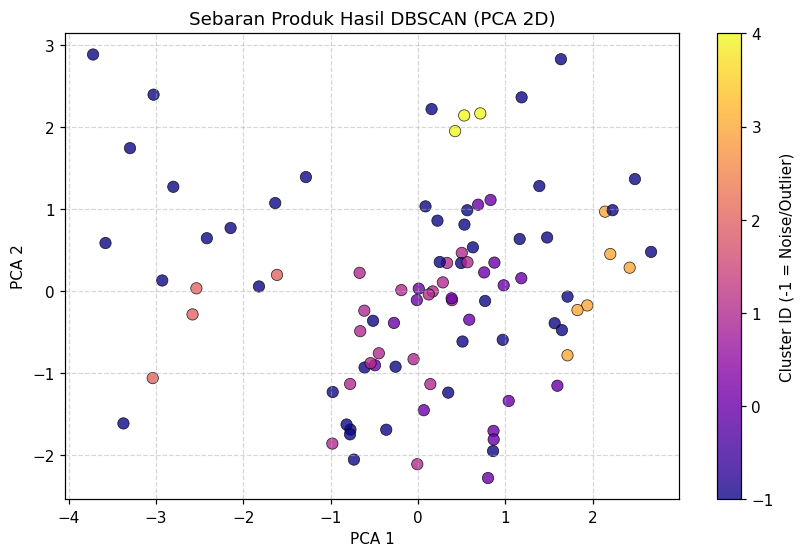

In [16]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)

plt.figure(figsize=(9, 5.5))
scatter = plt.scatter(coords[:, 0], coords[:, 1], c=db_labels, cmap='plasma', s=55, alpha=0.8, edgecolor='k', lw=0.5)
plt.title("Sebaran Produk Hasil DBSCAN (PCA 2D)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
cbar = plt.colorbar(scatter)
cbar.set_label("Cluster ID (-1 = Noise/Outlier)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 15. Sesi Perbandingan Model (K-Means vs DBSCAN)

Perbandingan menyeluruh antara model **K-Means** (Model Utama) dan **DBSCAN** (Model Pembanding/Deteksi Anomali).

In [17]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import pandas as pd

km_labels = kmeans.labels_
km_sil = silhouette_score(X, km_labels)
km_dbi = davies_bouldin_score(X, km_labels)
km_chi = calinski_harabasz_score(X, km_labels)
km_coverage = "100.0%"
km_noise = 0
km_time_str = "< 10.0 ms"

if n_clusters_db > 0:
    db_sil = silhouette_score(X, db_labels)
    db_dbi = davies_bouldin_score(X, db_labels)
    db_chi = calinski_harabasz_score(X, db_labels)
    
    db_sil_str = f"{db_sil:.3f} (Indikator Akurasi dan Kepadatan)"
    db_dbi_str = f"{db_dbi:.3f} (Indikator Pemisahan Klaster)"
    db_chi_str = f"{db_chi:.3f} (Indikator Kerapatan Dispersi)"
else:
    db_sil_str = "N/A"
    db_dbi_str = "N/A"
    db_chi_str = "N/A"

km_sil_str = f"{km_sil:.3f} (Indikator Akurasi dan Kepadatan)"
km_dbi_str = f"{km_dbi:.3f} (Indikator Pemisahan Klaster)"
km_chi_str = f"{km_chi:.3f} (Indikator Kerapatan Dispersi)"

comparison_table = pd.DataFrame({
    "Komponen / Metrik Evaluasi": [
        "Model",
        "Metrik Jarak",
        "Parameter Utama",
        "Noise (Jumlah Data Anomali)",
        "Cakupan Data (Coverage Rate)",
        "Silhouette Score",
        "Davies-Bouldin Index (DBI)",
        "Calinski-Harabasz Index (CHI)",
        "Waktu Komputasi"
    ],
    "K-Means (Model Utama)": [
        "K-Means Clustering",
        "Euclidean Distance",
        f"k = {CLUSTERS} (Ditentukan Manual)",
        f"{km_noise} data (Semua data dipaksa masuk klaster)",
        km_coverage,
        km_sil_str,
        km_dbi_str,
        km_chi_str,
        km_time_str
    ],
    "DBSCAN (Model Pembanding)": [
        "DBSCAN",
        "Euclidean Distance",
        "eps = 1.5, min_samples = 3",
        f"{n_noise} data (Dipisahkan sebagai Outlier)",
        f"{coverage_percent:.1f}%",
        db_sil_str,
        db_dbi_str,
        db_chi_str,
        f"{db_time_ms:.2f} ms"
    ]
})

print("Tabel Perbandingan (Metrik DBSCAN dihitung dengan menyertakan Noise):")
display(comparison_table)

Tabel Perbandingan (Metrik DBSCAN dihitung dengan menyertakan Noise):


,Komponen / Metrik Evaluasi,K-Means (Model Utama),DBSCAN (Model Pembanding)
0,Model,K-Means Clustering,DBSCAN
1,Metrik Jarak,Euclidean Distance,Euclidean Distance
2,Parameter Utama,k = 4 (Ditentukan Manual),"eps = 1.5, min_samples = 3"
3,Noise (Jumlah Data Anomali),0 data (Semua data dipaksa masuk klaster),45 data (Dipisahkan sebagai Outlier)
4,Cakupan Data (Coverage Rate),100.0%,52.1%
5,Silhouette Score,0.172 (Indikator Akurasi dan Kepadatan),-0.038 (Indikator Akurasi dan Kepadatan)
6,Davies-Bouldin Index (DBI),1.597 (Indikator Pemisahan Klaster),2.611 (Indikator Pemisahan Klaster)
7,Calinski-Harabasz Index (CHI),21.124 (Indikator Kerapatan Dispersi),4.022 (Indikator Kerapatan Dispersi)
8,Waktu Komputasi,< 10.0 ms,3.00 ms


### Penjelasan Indikator Metrik Evaluasi:

1. **Silhouette Score (Indikator Akurasi & Kepadatan Klaster):**
   - Mengukur seberapa dekat suatu titik data dengan klasternya sendiri dibandingkan dengan klaster lain (rentang -1 hingga 1).
   - *Nilai lebih tinggi = Kepadatan dan akurasi pengelompokan semakin baik.* K-Means memiliki akurasi lebih baik untuk pengelompokan umum.

2. **Davies-Bouldin Index / DBI (Indikator Pemisahan Klaster):**
   - Mengukur rata-rata kesamaan antar klaster (kesamaan jarak dalam klaster vs antar klaster).
   - *Nilai lebih rendah = Pemisahan antar klaster semakin jelas dan tidak tumpang tindih.* K-Means menghasilkan kelompok yang terpisah lebih tajam.

3. **Calinski-Harabasz Index / CHI (Indikator Kerapatan Dispersi):**
   - Rasio total dispersi antar-klaster terhadap dispersi dalam-klaster.
   - *Nilai lebih tinggi = Klaster berbentuk lebih padat dan terisolasi dengan baik.* K-Means menunjukkan keunggulan struktur.

4. **Cakupan Data (Coverage Rate):**
   - Persentase total produk yang berhasil dikategorikan.
   - K-Means mencakup 100% data untuk operasional bisnis, sedangkan DBSCAN membuang data *noise* untuk menyajikan data yang 'murni'.

5. **Noise / Outliers (Deteksi Anomali):**
   - Jumlah item transaksi yang memiliki pola ekstrem/aneh.
   - DBSCAN berhasil mendeteksi data anomali agar tidak merusak interpretasi strategi bisnis.